# Closing heat budgets in ACCESS-OM2

This recipe shows how to close the heat budget in ACCESS-OM2 using the MOM5 heat budget diagnostics, and how to organise the budget terms with [xbudget](https://xbudget.readthedocs.io/), a package for handling budgets diagnosed from ocean models with `xarray`.

For understanding these budgets, there are a few resources available:
- Summary of the heat budget in ESM2M (MOM5 based): https://mom-ocean.github.io/assets/pdfs/ESM2M_heat_budget.pdf
- Chapter 2.6 of the MOM5 manual: https://mom-ocean.github.io/assets/pdfs/MOM5_manual.pdf

This recipe will not describe all the details of how the budgets work, as these are described in the above resources. Instead, we focus on the terms that are required to close the budget.

We use the 1/4-degree OMIP-2 experiment `025deg_jra55_iaf_omip2_cycle6`, as it has monthly output of all the heat budget diagnostics.

Note that the terms included in the budget depend on whether various parameterizations are active or not in the specific experiment you are interested in. For example, the 1/10th degree simulations do not include the GM or Redi diffusion mesoscale parameterizations. We will note these differences where possible.

#### Adapting for MOM6

`xbudget` comes with ready-made budget definitions for MOM6, e.g. `xbudget.load_preset_budget(model="MOM6_3Donly")`. These use MOM6's own heat budget diagnostics (`opottemptend`, `T_advection_xy`, `Th_tendency_vert_remap`, `opottemppmdiff`, `opottempdiff`, `boundary_forcing_heat_tendency`, ...) multiplied by `areacello`, in place of the MOM5 diagnostics and the hand-written budget definition below. The rest of the recipe works the same way, provided the run saved those diagnostics.

## The 3D Eulerian heat budget

The ACCESS-OM2/CM2 (i.e. MOM5) heat budget can be expressed as follows:

$$
\begin{aligned}
\texttt{temp\_tendency} = {} & \texttt{temp\_advection} + \texttt{temp\_submeso} \\
& + \texttt{temp\_vdiffuse\_diff\_cbt} + \texttt{temp\_nonlocal\_KPP} \\
& + \texttt{sw\_heat} + \texttt{temp\_rivermix} + \texttt{temp\_vdiffuse\_sbc} + \texttt{sfc\_hflux\_pme} \\
& + \texttt{frazil\_3d} \\
& + \texttt{temp\_vdiffuse\_k33} + \texttt{neutral\_diffusion\_temp} + \texttt{neutral\_gm\_temp} \\
& + \texttt{mixdownslope\_temp} + \texttt{temp\_sigma\_diff} + \texttt{temp\_eta\_smooth}
\end{aligned}
$$

All terms are in units of W m$^{-2}$ corresponding to the heat content tendency per unit area within each grid cell. I.e. the `temp_tendency` term is given by:

$$
\frac{\partial}{\partial t}\left(\rho_0 C_p\Theta \Delta z\right)
$$

where $\Delta z$ is the time variable grid cell thickness, $\rho_0=1035$ kg m$^{-3}$ is the reference density, $C_p=3992.10322329649$ J kg$^{-1}$ $^\circ$C$^{-1}$ is the specific heat and $\Theta$ is Conservative Temperature ([McDougall 2003](https://doi.org/10.1175/1520-0485(2003)033%3C0945:PEACOV%3E2.0.CO;2), effectively a temperature variable constructed such that we can use a constant specific heat). It is important to note that this is a *heat* budget not a temperature budget, and thus the time variability of the vertical grid thicknesses must be taken into account.

The terms can be described as follows:

- `temp_advection` is the convergence of the three-dimensional resolved advection (this can be split into components by taking the convergence of the `temp_xflux_adv`, `temp_yflux_adv` and `temp_zflux_adv` terms, but note that one must be careful with the interpretation of these terms as they may or may not depend on the arbitrary reference temperature).
- `temp_submeso` is the convergence of the three-dimensional parameterized submesoscale advection (generally pretty small, [Fox-Kemper et al. 2009](https://doi.org/10.1175/2007JPO3792.1)).
- `temp_vdiffuse_diff_cbt` and `temp_nonlocal_KPP` are the vertical mixing terms. The first corresponds to the diffusive terms including [KPP](https://doi.org/10.1029/94RG01872) boundary layer diffusion, shear-driven interior diffusion, background diffusion (whose formulation differs depending on the configuration/resolution), double-diffusive mixing and bottom-intensified tidal mixing ([Simmons et al. 2004](https://doi.org/10.1016/S1463-5003(03)00011-8)). The second term is the non-local flux term within the KPP boundary layer scheme.
- `temp_rivermix` is a heat source associated with the mixing of riverwaters (this is 3D - the scheme mixes the riverwater across the top 4 grid cells).
- `temp_vdiffuse_sbc` captures non-volume-flux-related surface heat fluxes (latent, sensible, longwave and the net incident shortwave). All of it, including the shortwave that actually penetrates below the surface layer, is deposited in the surface layer; `sw_heat` then moves the penetrating part down. This is a 2D term.
- `sw_heat` accounts for the penetration of shortwave radiation into the ocean. It is a redistribution term: it is large and negative in the surface layer (removing the part of the shortwave in `temp_vdiffuse_sbc` that penetrates deeper) and positive below, where that shortwave is absorbed. Shortwave that reaches the bottom cell is absorbed there, so `sw_heat` sums to exactly zero in the vertical.
- `sfc_hflux_pme` captures volume-flux associated surface heat fluxes, including precipitation, evaporation and river run-off. These processes add heat to the ocean through the addition of volume (in MOM5 precipitation enters the surface ocean at the surface temperature).
- `frazil_3d` is the heat source due to the formation of frazil ice. This is 3-dimensional as frazil can be formed below the surface layer. Note that in later ACCESS-OM2 runs a new 2D diagnostic `frazil_3d_int_z` was added that corresponds to the vertical integral of `frazil_3d` (this is distinct from `frazil_2d` which only includes the surface layer!).
- `temp_vdiffuse_k33` and `neutral_diffusion_temp` are parameterized along-isopycnal diffusion terms ([Redi 1982](https://doi.org/10.1175/1520-0485(1982)012%3C1154:OIMBCR%3E2.0.CO;2)). These terms are active at 1-degree and most 1/4-degree configurations, but not at 1/10-degree.
- `neutral_gm_temp` is parameterization advection by mesoscale eddies ([Gent and McWilliams 1990](https://doi.org/10.1175/1520-0485(1990)020%3C0150:IMIOCM%3E2.0.CO;2)). This term is active at 1-degree and most 1/4-degree configurations, but not at 1/10-degree. Note that the Gent and McWilliams scheme is implemented as skew-diffusion (see [Griffies 1998](https://doi.org/10.1175/1520-0485(1998)028<0831:TGMSF>2.0.CO;2)), not as an additional eddy-induced advection (this influences, in particular, the interpretation of its components, `temp_xflux_gm`, `temp_yflux_gm`, `temp_zflux_gm`).
- `mixdownslope_temp` and `temp_sigma_diff` are miscellaneous mixing terms only active in the 1-degree version.
- `temp_eta_smooth` is the heat transport convergence associated with the SSH smoothing operator included to prevent numerical checkerboard instabilities on a B-grid (another small term). Active in all configurations.

## Surface heat flux components

See issue: https://github.com/COSIMA/access-om2/issues/139

The total heat flux into the ocean from surface forcing and ice-ocean exchanges is:

`net_sfc_heating + frazil_3d_int_z`

where,

`net_sfc_heating = sfc_hflux_coupler + sfc_hflux_pme + sfc_hflux_from_runoff + sfc_hflux_from_calving`

`sfc_hflux_coupler = swflx + lw_heat + fprec_melt_heat + calving_melt_heat + sens_heat + evap_heat + mh_flux + liceht`

Note the calving terms and `liceht` are currently zero in ACCESS-OM.

The vertical sum of the 3D Eulerian heat budget diagnostic `temp_vdiffuse_sbc` and `frazil_3d` will give the same result as `net_sfc_heating` + `frazil_3d_int_z`.

## Loading the budget diagnostics

First, import the required packages and start a `dask` client.

In [1]:
import copy

import intake
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import xbudget

from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 28
Total threads: 28,Total memory: 112.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33573,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:46071,Total threads: 1
Dashboard: http://127.0.0.1:38761/status,Memory: 4.00 GiB
Nanny: tcp://127.0.0.1:43839,


We look at a single month. The output is stored in yearly files, so we restrict each catalog search to the file for that year (its `end_date` is in that year). This avoids opening every file of the experiment.

In [3]:
catalog = intake.cat.access_nri
experiment = '025deg_jra55_iaf_omip2_cycle6'
cat = catalog[experiment]

year = '1958'
month = '1958-01'

Most budget terms are 3D, but two (`sfc_hflux_pme` and `temp_eta_smooth`) are 2D column tendencies. `mixdownslope_temp` and `temp_sigma_diff` are only active in the 1-degree configuration, so they are not available for this experiment and are skipped.

In [4]:
terms_3D = ['temp_tendency', 'temp_advection', 'temp_submeso', 'neutral_gm_temp',
            'temp_vdiffuse_diff_cbt', 'temp_nonlocal_KPP', 'neutral_diffusion_temp',
            'temp_vdiffuse_k33', 'mixdownslope_temp', 'temp_sigma_diff',
            'temp_vdiffuse_sbc', 'sw_heat', 'temp_rivermix', 'frazil_3d']
terms_2D = ['sfc_hflux_pme', 'temp_eta_smooth']

ds = xr.Dataset()
for term in terms_3D + terms_2D:
    search = cat.search(variable=term, frequency='1mon', end_date=f'{year}.*')
    if len(search.df) == 0:
        print(f'{term} is not available for {experiment}; skipping it')
        continue
    da = search.to_dask(xarray_open_kwargs={'decode_timedelta': False})[term]
    ds[term] = da.sel(time=month).squeeze('time', drop=True)

mixdownslope_temp is not available for 025deg_jra55_iaf_omip2_cycle6; skipping it
temp_sigma_diff is not available for 025deg_jra55_iaf_omip2_cycle6; skipping it


All the budget terms are heat content tendencies per unit area (W m$^{-2}$), so we also need the area of each tracer cell, `area_t`, to turn them into tendencies in W.

In [5]:
area_search = cat.search(variable='area_t', frequency='fx')
area_t = xr.open_dataset(area_search.df.path[0])['area_t']
ds['area_t'] = area_t.reset_coords(drop=True)

To keep every term on the same 3D grid, we put the 2D terms in the top layer (and zeros below). Then every term is defined on `(st_ocean, yt_ocean, xt_ocean)`, the budget closes in every grid cell, and a vertical sum counts the 2D terms exactly once.

In [6]:
surface = ds.st_ocean.isel(st_ocean=0)
for term in terms_2D:
    if term in ds:
        ds[term] = (ds[term].expand_dims(st_ocean=ds.st_ocean)
                            .where(ds.st_ocean == surface, 0.)
                            .transpose('st_ocean', ...))

ds = ds.load()

## Defining the budget for xbudget

`xbudget` describes a budget as a nested dictionary. Each tracer (here `heat`) has a left-hand side (`lhs`, the tendency) and a right-hand side (`rhs`, the processes that cause it). Each entry is built from the diagnostics with a `sum` or a `product`, and the sums can be nested to group related processes, e.g. all the advective terms. Every entry also has a `var` key, which `xbudget` fills in with the name of the variable it computes.

We group the parameterised mesoscale eddy terms (GM, neutral diffusion and `k33`) with advection rather than with diffusion: they represent eddy stirring, which at higher resolution is resolved and so appears in `temp_advection` instead. This also makes it easier to compare budgets across resolutions.

Every MOM5 term here is a heat content tendency per unit area, so each one is the product of a diagnostic and `area_t`. Two small helper functions keep the dictionary short. A term whose diagnostic is not available for this experiment is set to `None`, which `xbudget` ignores. (If we kept it, `xbudget` would warn and use zero in its place.)

In [7]:
def term(diagnostic):
    """Heat content tendency (W) = diagnostic (W m-2) x cell area (m2)."""
    if diagnostic not in ds:
        return None    # not available for this experiment
    return {'var': None,
            'product': {'var': None,
                        'tracer_content_tendency_per_unit_area': diagnostic,
                        'area': 'area_t'}}

def group(**terms):
    """Sum of several terms."""
    return {'var': None, 'sum': {'var': None, **terms}}

In [8]:
mom5_heat_budget = {
    'heat': {
        'lhs': group(Eulerian_tendency=term('temp_tendency')),
        'rhs': group(
            advection=group(
                resolved=term('temp_advection'),
                submesoscale=term('temp_submeso'),
                GM=term('neutral_gm_temp'),
                neutral=term('neutral_diffusion_temp'),
                k33=term('temp_vdiffuse_k33'),
            ),
            vertical_diffusion=group(
                diffusive=term('temp_vdiffuse_diff_cbt'),
                KPP_nonlocal=term('temp_nonlocal_KPP'),
            ),
            mixdownslope=term('mixdownslope_temp'),
            sigma_diffusion=term('temp_sigma_diff'),
            surface_exchange_flux=group(
                nonadvective=term('temp_vdiffuse_sbc'),
                shortwave_penetration=term('sw_heat'),
                mass_flux=term('sfc_hflux_pme'),
                rivers=term('temp_rivermix'),
            ),
            frazil_ice=term('frazil_3d'),
            eta_smoothing=term('temp_eta_smooth'),
        ),
    }
}

`xbudget.collect_budgets` computes every entry and adds it to `ds`. We pass a copy of the dictionary because `collect_budgets` fills in the `var` keys in place.

In [9]:
budget = copy.deepcopy(mom5_heat_budget)
xbudget.collect_budgets(ds, budget)

`xbudget.aggregate` gives a summary of the budget: the name of the variable in `ds` for each term.

In [10]:
summary = xbudget.aggregate(budget)
summary

{'heat': {'lhs': {'Eulerian_tendency': 'heat_lhs_sum_Eulerian_tendency'},
  'rhs': {'advection': 'heat_rhs_sum_advection',
   'vertical_diffusion': 'heat_rhs_sum_vertical_diffusion',
   'surface_exchange_flux': 'heat_rhs_sum_surface_exchange_flux',
   'frazil_ice': 'heat_rhs_sum_frazil_ice',
   'eta_smoothing': 'heat_rhs_sum_eta_smoothing'}}}

## Checking that the budget closes

In [11]:
lhs = ds[budget['heat']['lhs']['var']]
rhs = ds[budget['heat']['rhs']['var']]
residual = lhs - rhs

print(f"largest residual in a grid cell, relative to the largest tendency: "
      f"{float(np.abs(residual).max() / np.abs(lhs).max()):.1e}")
print(f"global heat content tendency: {float(lhs.sum()) / 1e12:.3f} TW (LHS), "
      f"{float(rhs.sum()) / 1e12:.3f} TW (RHS)")

largest residual in a grid cell, relative to the largest tendency: 8.4e-07


global heat content tendency: -487.257 TW (LHS), -487.258 TW (RHS)


The residual is at round-off level, so the budget closes. To plot the terms, we sum them over depth and divide by the cell area, which gives the vertically integrated budget in W m$^{-2}$.

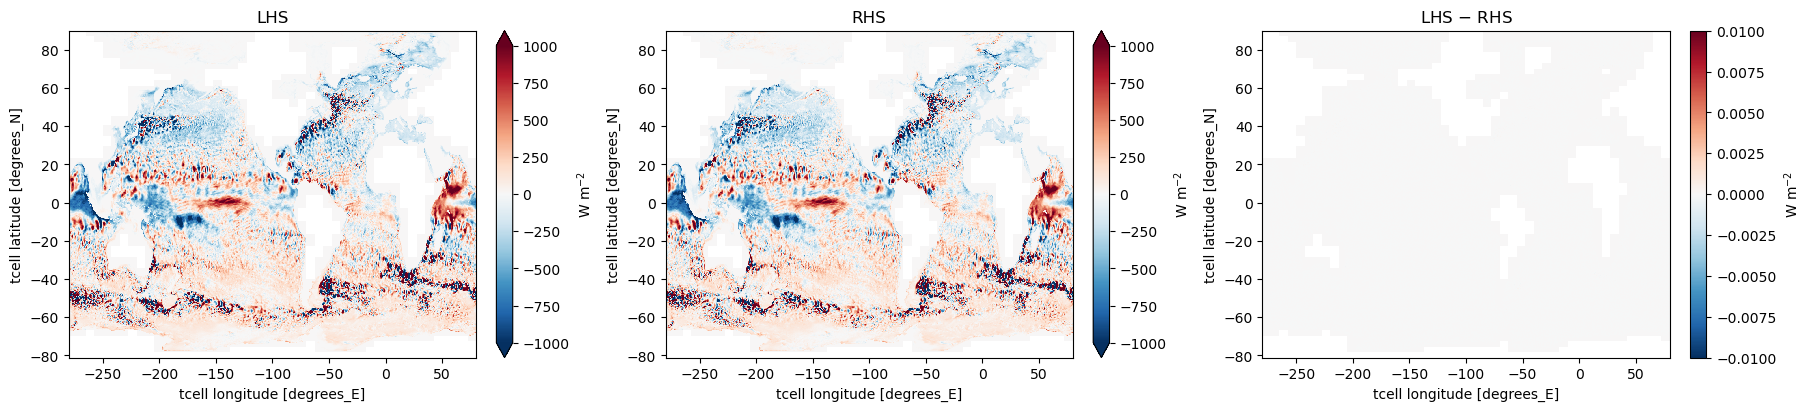

In [12]:
def column_per_area(da):
    return (da.sum('st_ocean') / ds.area_t).rename(da.name)

fig, axs = plt.subplots(1, 3, figsize=(18, 4), layout='constrained')
for ax, da, title in zip(axs, [lhs, rhs, residual], ['LHS', 'RHS', 'LHS $-$ RHS']):
    vmax = 1e3 if title != 'LHS $-$ RHS' else 1e-2
    column_per_area(da).plot(ax=ax, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                             cbar_kwargs={'label': 'W m$^{-2}$'})
    ax.set_title(title)

## The terms of the vertically integrated budget

The right-hand side, grouped as in the dictionary above. The terms differ in size by orders of magnitude, so each panel has its own colour scale (`robust=True` sets it from the 2nd and 98th percentiles).

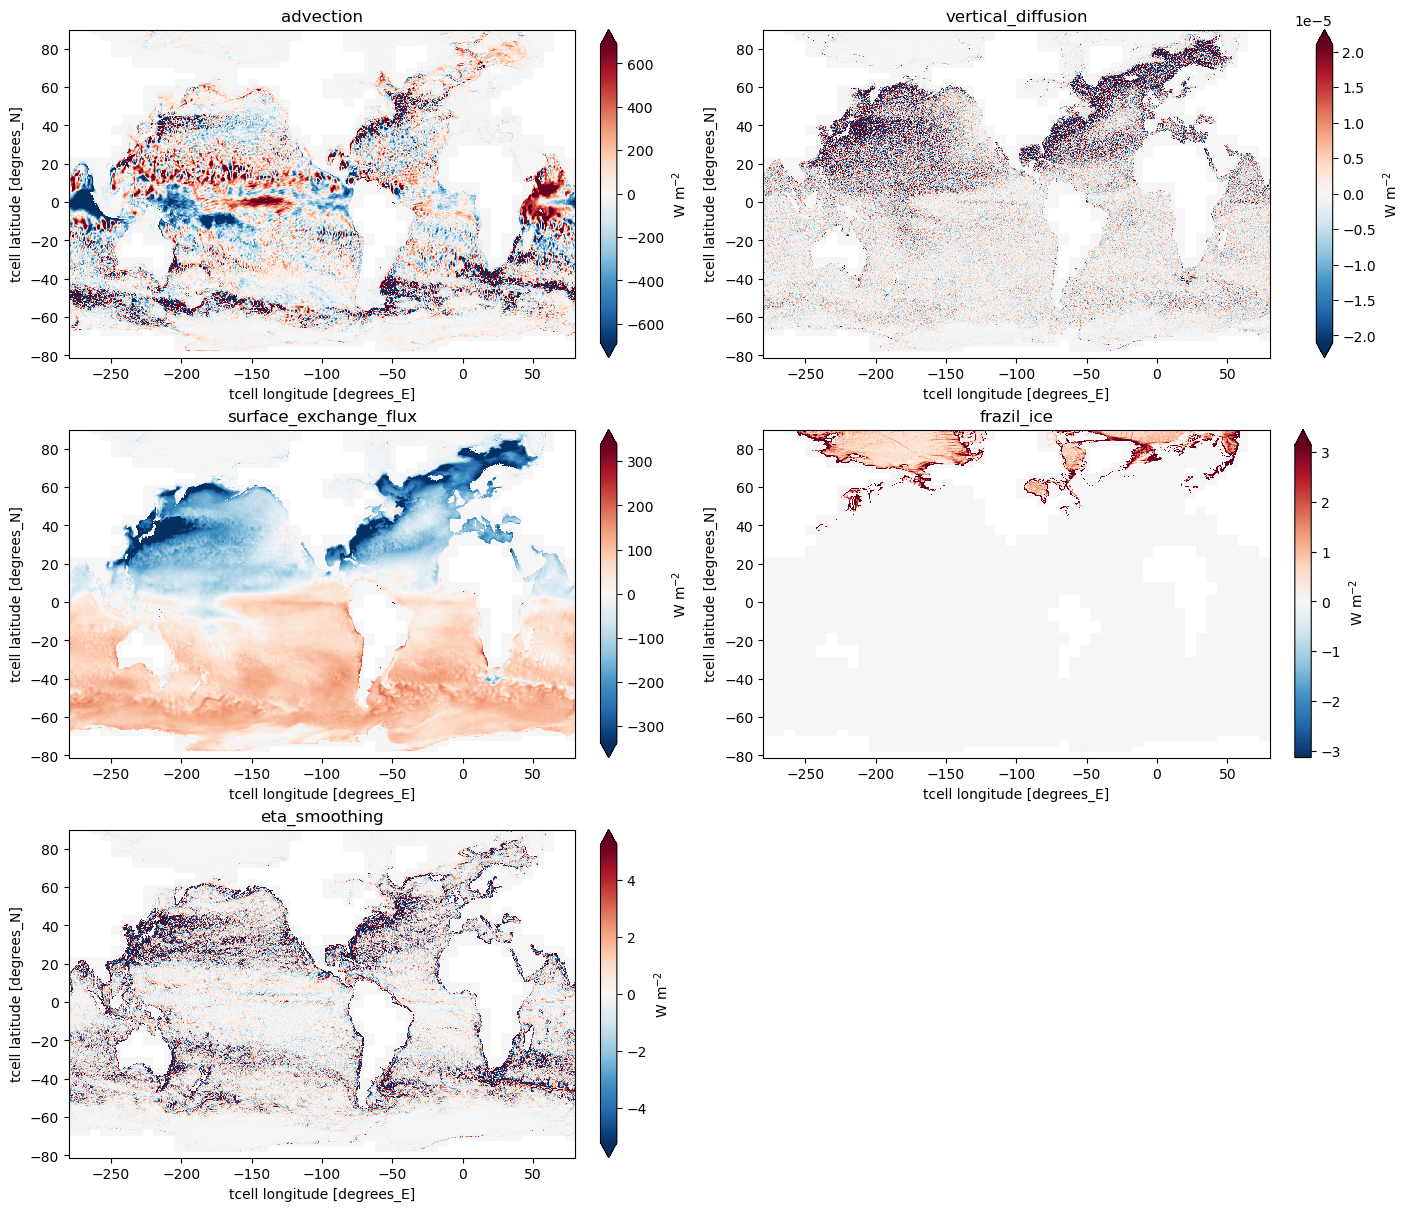

In [13]:
rhs_terms = summary['heat']['rhs']

fig, axs = plt.subplots(3, 2, figsize=(14, 12), layout='constrained')
for ax, (name, var) in zip(axs.flat, rhs_terms.items()):
    column_per_area(ds[var]).plot(ax=ax, cmap='RdBu_r', center=0, robust=True,
                                  cbar_kwargs={'label': 'W m$^{-2}$'})
    ax.set_title(name)
for ax in axs.flat[len(rhs_terms):]:
    ax.remove()

`xbudget.aggregate` can also split a group into its parts with `decompose`.

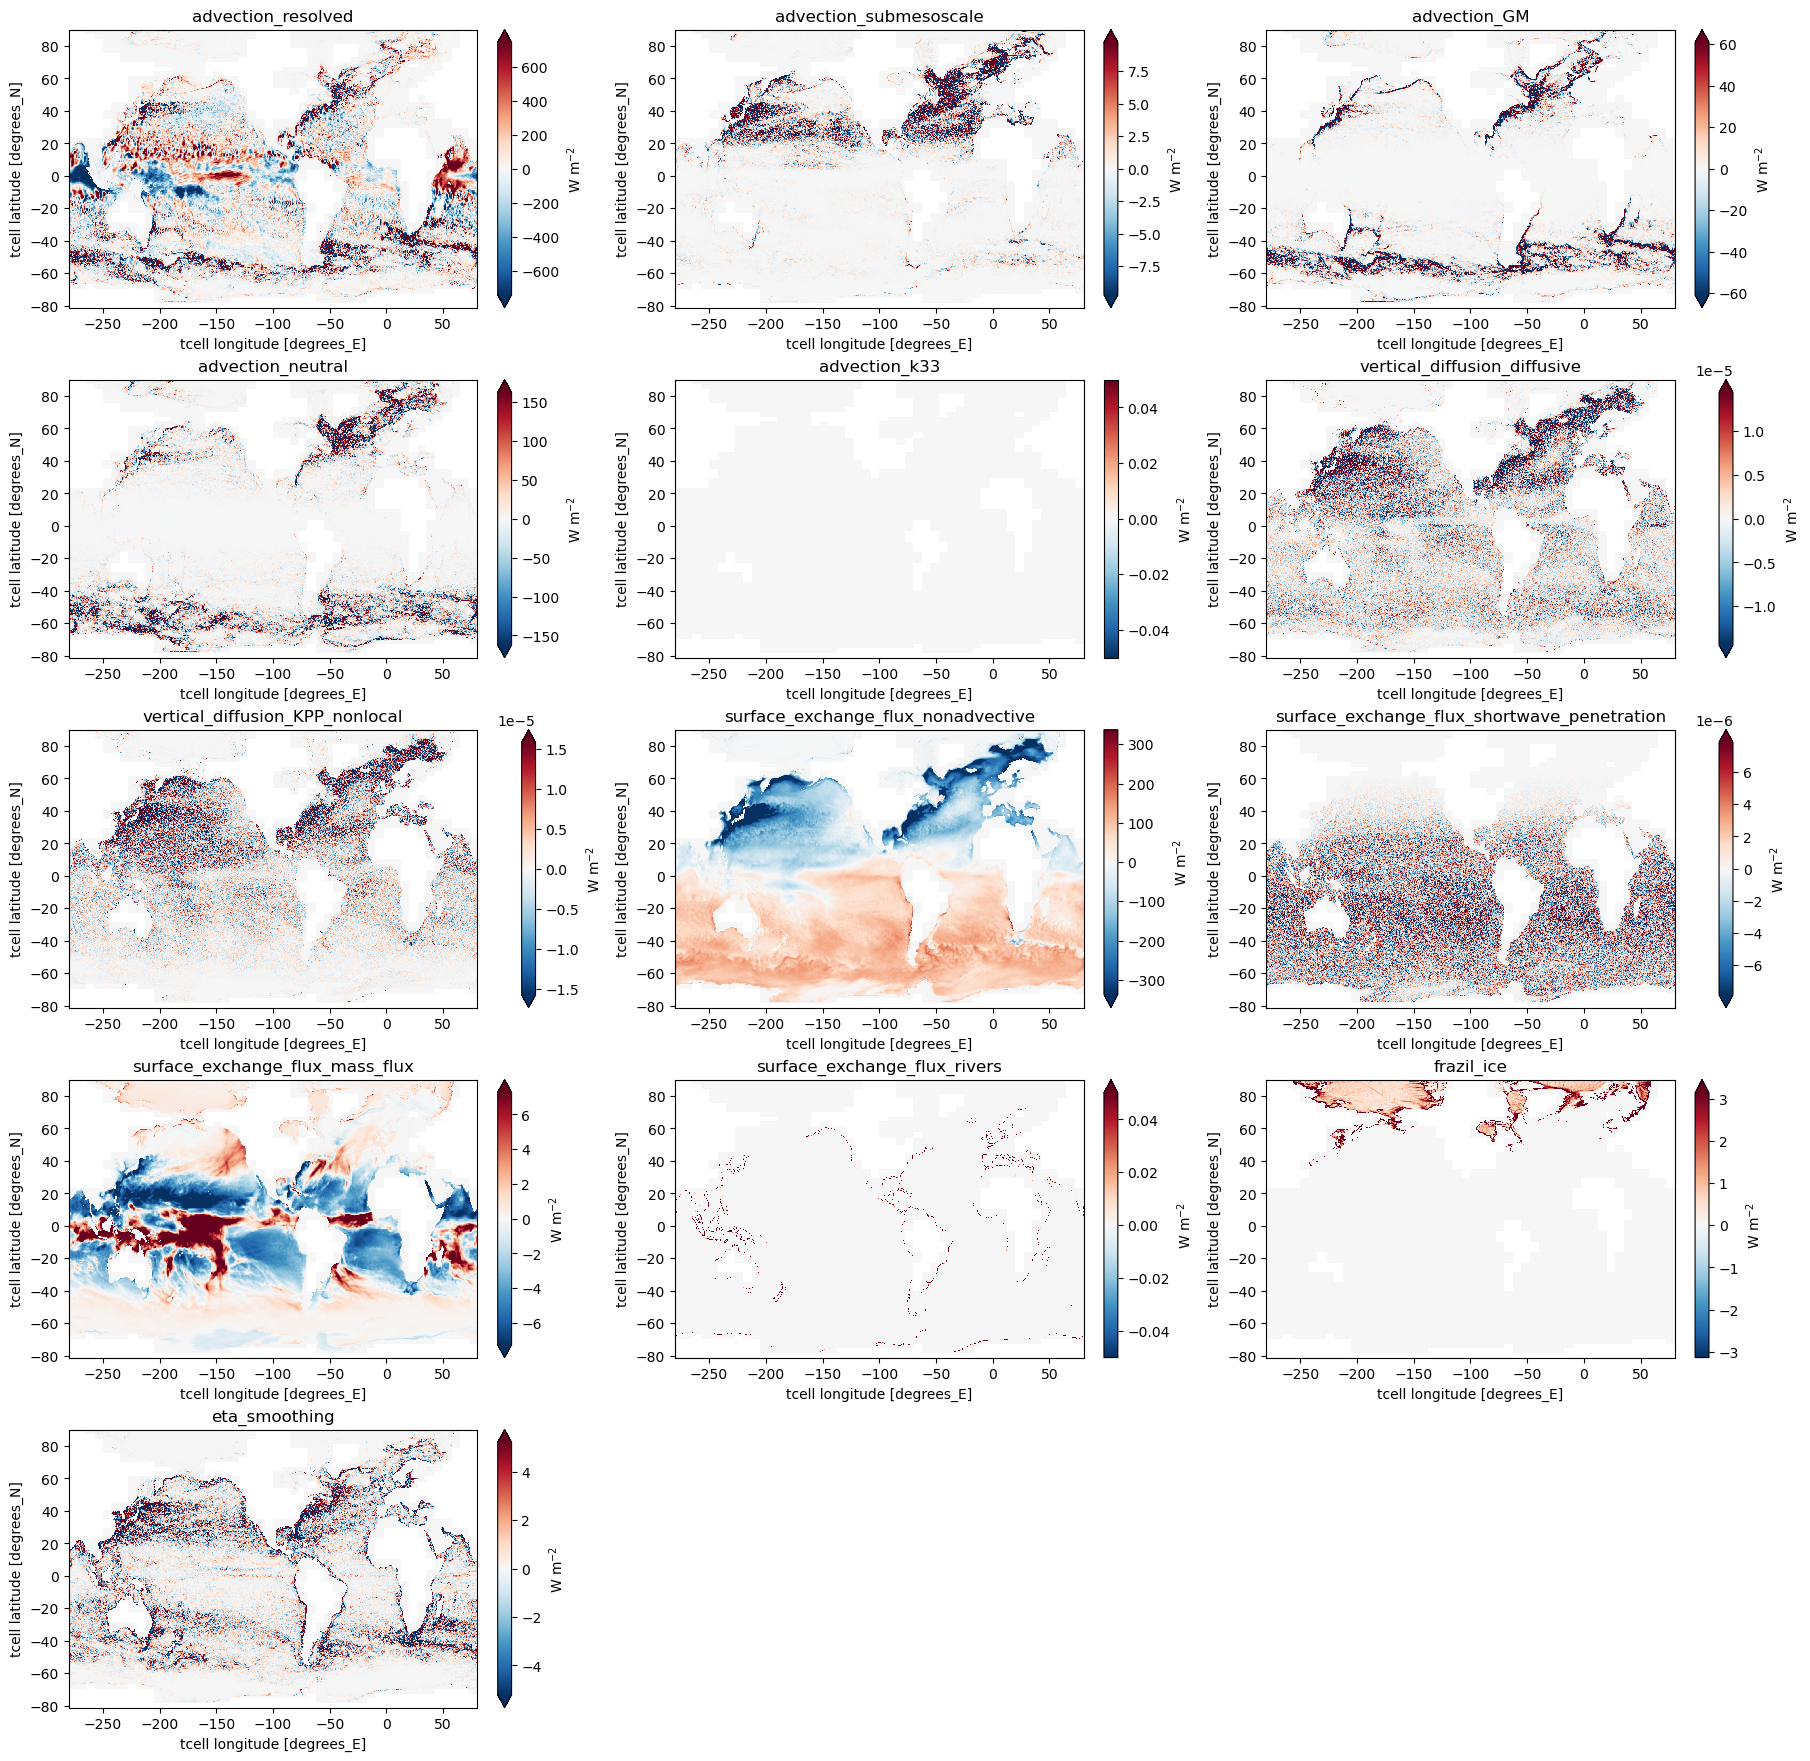

In [14]:
decomposed = xbudget.aggregate(budget, decompose=['advection', 'vertical_diffusion', 'surface_exchange_flux'])
terms = decomposed['heat']['rhs']

ncols = 3
nrows = int(np.ceil(len(terms) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.5 * nrows), layout='constrained')
for ax, (name, var) in zip(axs.flat, terms.items()):
    column_per_area(ds[var]).plot(ax=ax, cmap='RdBu_r', center=0, robust=True,
                                  cbar_kwargs={'label': 'W m$^{-2}$'})
    ax.set_title(name)
for ax in axs.flat[len(terms):]:
    ax.remove()

Note the colour scales: vertical diffusion (`temp_vdiffuse_diff_cbt`), the KPP non-local term (`temp_nonlocal_KPP`) and shortwave penetration (`sw_heat`) only move heat up and down within a column, so their vertical integrals are close to zero (about $10^{-5}$ W m$^{-2}$ here). They matter for the 3D budget, but not for the vertically integrated one.

The global integral of each term shows how the heat content tendency is made up. Advection and vertical diffusion only move heat around, so they integrate to (almost) zero; the global tendency is set by the surface fluxes and frazil formation.

In [15]:
for name, var in terms.items():
    print(f'{name:45s} {float(ds[var].sum()) / 1e12:+9.3f} TW')

advection_resolved                               +0.000 TW


advection_submesoscale                           -0.000 TW


advection_GM                                     +0.000 TW


advection_neutral                                +0.000 TW


advection_k33                                    +0.000 TW


vertical_diffusion_diffusive                     -0.001 TW


... (3 outputs left out)

surface_exchange_flux_mass_flux                -182.579 TW


surface_exchange_flux_rivers                    +76.808 TW


frazil_ice                                      +50.228 TW


eta_smoothing                                    -0.000 TW


## Other subjects that could/should be treated here:
- Numerical accuracy of the budget; issues with time-averaging, rounding errors etc.
- Dependence of the budget on the arbitrary reference temperature (e.g. Kelvin vs. Celsius), in particular interpretation of the components of advection given non-zero mass fluxes.
- Helmholtz decompositions of the vertically-integrated heat transport ([Forget and Ferreira 2019](https://doi.org/10.1038/s41561-019-0333-7)).
- Relating tendencies to the evolution of the time-averaged tracer content ('hat-averaging', [Bladwell et al. 2026](https://egusphere.copernicus.org/preprints/2026/egusphere-2026-3672/)).
- Mixed layer budgets, including issues with trying to compute these offline (see [Holmes and Malan 2026](https://doi.org/10.22541/essoar.15005159/v1) and the [access-om2-sst-budget](https://github.com/rmholmes/access-om2-sst-budget) repository).
- Closing salt budgets